# Bài 22: Đồ án Cuối khóa (Capstone Project) — Xây dựng Hệ thống Phân loại Ảnh End-to-End, Phân tích Lỗi và Hướng dẫn Mở rộng

## 1. Mục tiêu Đồ án
Kết nối toàn bộ kiến thức từ Bài 00 đến Bài 21 vào một quy trình kỹ thuật khép kín (**End-to-End Pipeline**):
1. **Đặc tả Bài toán & Kiểm định Dữ liệu (`Data Auditing`)**: Kiểm tra kích thước, kênh màu, phân phối lớp, giá trị khuyết/hỏng.
2. **Chia Dữ liệu Chuẩn (`Train / Validation / Test`)**: Không rò rỉ dữ liệu (`Zero Data Leakage`).
3. **Xây dựng Đường cơ sở ML Truyền thống (`Classical ML Baseline`)**: `HOG + Color + LBP` kết hợp `SVM`.
4. **Huấn luyện Mô hình Học sâu (`Deep Learning Pipeline`)**: `ResidualCNN` kèm `Augmentation` trên tập Train, theo dõi `Train/Val Loss & Accuracy`, lưu `Checkpoint` tốt nhất.
5. **Đánh giá Toàn diện trên Tập Test (`Comprehensive Evaluation`)**: Báo cáo `Accuracy`, `Macro-F1`, `Weighted-F1`, bảng `Precision/Recall/Specificity` từng lớp và `Confusion Matrix`.
6. **Phân tích Lỗi Sâu (`Error Analysis`)**: Tìm những mẫu bị dự đoán sai có `loss` cao nhất để hiểu giới hạn của mô hình.
7. **Chương trình Suy luận Độc lập (`Standalone Inference`)** & **Hướng dẫn Thay bằng Bộ Ảnh Cá nhân của Bạn**.
8. **Bảng Tiêu chí Tự Đánh giá Đồ án (`Self-Assessment Rubric`)**.

> **Lưu ý trung thực khoa học**: Kết quả chạy mặc định trên bộ dữ liệu tổng hợp cỡ nhỏ trong notebook này dùng để xác nhận toàn bộ quy trình kỹ thuật của bạn hoạt động chính xác từ đầu đến cuối; **không dùng con số trên dữ liệu nhỏ này để khẳng định mô hình đã sẵn sàng triển khai thương mại** nếu chưa kiểm định trên dữ liệu thực tế quy mô lớn.

## 2. Thời gian thực hiện dự kiến
- Khoảng **4.0 – 6.0 giờ** (bao gồm cả phần tự thử nghiệm mở rộng).


In [1]:
# Cell 1: Bước 1 & 2 — Đặc tả Bài toán, Kiểm định Dữ liệu (Data Audit) và Chia Tập Train/Val/Test
import sys
import json
from pathlib import Path

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if (project_root / "image_ai_learning").is_dir():
    project_root = project_root / "image_ai_learning"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from src.utils import set_seed, get_device, count_parameters, save_checkpoint, load_checkpoint
from src.synthetic_data import generate_synthetic_shapes_dataset
from src.features import extract_combined_features
from src.models import ResidualCNN
from src.training import fit_classifier, evaluate_classifier
from src.evaluation import compute_classification_metrics

QUICK_RUN = True
SEED = 42
set_seed(SEED)
device = get_device()

n_total = 320 if QUICK_RUN else 800
capstone_ds = generate_synthetic_shapes_dataset(num_samples=n_total, image_size=32, seed=SEED, noise_std=12.0)
images_np = capstone_ds["images"]
labels_np = capstone_ds["labels"]
class_names = capstone_ds["class_names"]

# Kiểm định chất lượng dữ liệu tự động (Automated Data Audit)
assert images_np.ndim == 4 and images_np.shape[1:] == (32, 32, 3), "Sai kích thước ảnh!"
assert images_np.dtype == np.uint8, "Ảnh gốc phải ở kiểu uint8!"
assert len(images_np) == len(labels_np), "Số lượng ảnh và nhãn không khớp!"

idx_all = np.arange(len(images_np))
idx_tr, idx_temp = train_test_split(idx_all, test_size=0.30, random_state=SEED, stratify=labels_np)
idx_va, idx_te = train_test_split(idx_temp, test_size=0.50, random_state=SEED, stratify=labels_np[idx_temp])

print("=== BÁO CÁO KIỂM ĐỊNH DỮ LIỆU ĐỒ ÁN (DATA AUDIT) ===")
print(f"Tổng số mẫu: {len(images_np)} | Kích thước: {images_np.shape[1:]} | Các lớp: {class_names}")
print(f"Chia tập Stratified -> Train: {len(idx_tr)} ({np.bincount(labels_np[idx_tr]).tolist()}), Val: {len(idx_va)}, Test: {len(idx_te)}")


=== BÁO CÁO KIỂM ĐỊNH DỮ LIỆU ĐỒ ÁN (DATA AUDIT) ===
Tổng số mẫu: 320 | Kích thước: (32, 32, 3) | Các lớp: ['circle', 'square', 'triangle', 'cross']
Chia tập Stratified -> Train: 224 ([56, 56, 56, 56]), Val: 48, Test: 48


In [2]:
# Cell 2: Bước 3 — Xây dựng Baseline Machine Learning Truyền thống (HOG+Color+LBP + RBF SVM)
feats_all = extract_combined_features(images_np, cell_size=8)
scaler_bl = StandardScaler()
X_tr_bl = scaler_bl.fit_transform(feats_all[idx_tr])
X_va_bl = scaler_bl.transform(feats_all[idx_va])
X_te_bl = scaler_bl.transform(feats_all[idx_te])

baseline_svm = SVC(C=2.0, kernel="rbf", probability=True, random_state=SEED).fit(X_tr_bl, labels_np[idx_tr])
bl_val_metrics = compute_classification_metrics(labels_np[idx_va], baseline_svm.predict(X_va_bl), class_names)
bl_test_metrics = compute_classification_metrics(labels_np[idx_te], baseline_svm.predict(X_te_bl), class_names)

print(f"[Baseline ML - SVM] Val Acc : {bl_val_metrics['accuracy']*100:.1f}% | Val Macro-F1 : {bl_val_metrics['macro_f1']:.4f}")
print(f"[Baseline ML - SVM] Test Acc: {bl_test_metrics['accuracy']*100:.1f}% | Test Macro-F1: {bl_test_metrics['macro_f1']:.4f}")


[Baseline ML - SVM] Val Acc : 89.6% | Val Macro-F1 : 0.8949
[Baseline ML - SVM] Test Acc: 93.8% | Test Macro-F1: 0.9375


In [3]:
# Cell 3: Bước 4 — Huấn luyện Mô hình Deep Learning (ResidualCNN) với Augmentation trên Tập Train
X_all_t = torch.from_numpy(images_np).permute(0, 3, 1, 2).float() / 255.0
y_all_t = torch.from_numpy(labels_np).long()

tr_mean = X_all_t[idx_tr].mean(dim=(0, 2, 3), keepdim=True)
tr_std = X_all_t[idx_tr].std(dim=(0, 2, 3), keepdim=True) + 1e-6
X_norm_t = (X_all_t - tr_mean) / tr_std

# Tăng cường dữ liệu (Augmentation) CHỈ TRÊN TẬP TRAIN: ghép thêm bản lật ngang và lật dọc (bảo toàn nhãn của cả 4 hình đối xứng!)
X_tr_aug = torch.cat([X_norm_t[idx_tr], torch.flip(X_norm_t[idx_tr], dims=[3])], dim=0)
y_tr_aug = torch.cat([y_all_t[idx_tr], y_all_t[idx_tr]], dim=0)

tr_loader = DataLoader(TensorDataset(X_tr_aug, y_tr_aug), batch_size=32, shuffle=True, num_workers=0)
va_loader = DataLoader(TensorDataset(X_norm_t[idx_va], y_all_t[idx_va]), batch_size=32, shuffle=False, num_workers=0)
te_loader = DataLoader(TensorDataset(X_norm_t[idx_te], y_all_t[idx_te]), batch_size=32, shuffle=False, num_workers=0)

capstone_model = ResidualCNN(in_channels=3, num_classes=4, base_channels=16).to(device)
print("ResidualCNN Capstone Parameters:", count_parameters(capstone_model))

crit = nn.CrossEntropyLoss()
opt_dl = torch.optim.AdamW(capstone_model.parameters(), lr=2.5e-3, weight_decay=1e-4)
sched_dl = torch.optim.lr_scheduler.CosineAnnealingLR(opt_dl, T_max=14 if QUICK_RUN else 30, eta_min=1e-4)
ckpt_capstone = project_root / "outputs" / "checkpoints" / "capstone_residual_cnn_best.pt"

preproc_metadata = {
    "image_size": 32,
    "mean": tr_mean.squeeze().tolist(),
    "std": tr_std.squeeze().tolist(),
    "color_space": "RGB",
}

hist_dl = fit_classifier(
    model=capstone_model,
    train_loader=tr_loader,
    val_loader=va_loader,
    criterion=crit,
    optimizer=opt_dl,
    device=device,
    epochs=14 if QUICK_RUN else 30,
    scheduler=sched_dl,
    patience=8,
    checkpoint_path=ckpt_capstone,
    class_names=class_names,
    preprocessing_config=preproc_metadata,
)
print(f"ResidualCNN Best Epoch: {hist_dl['best_epoch']} | Best Val Accuracy: {hist_dl['best_val_acc']*100:.1f}%")


ResidualCNN Capstone Parameters: {'total': 77652, 'trainable': 77652, 'frozen': 0}
ResidualCNN Best Epoch: 14 | Best Val Accuracy: 95.8%


=== BẢNG TỔNG KẾT ĐÁNH GIÁ TRÊN TẬP TEST (BASELINE ML VS DEEP LEARNING) ===
                                      Approach  Test_Acc  Test_Macro_F1
1. Classical ML Baseline (HOG+Color+LBP + SVM)    0.9375         0.9375
 2. Deep Learning (ResidualCNN + Augmentation)    0.8958         0.8957

=== BẢNG METRIC TỪNG LỚP CỦA MÔ HÌNH DEEP LEARNING ===
          precision  recall  specificity      f1  support
circle       0.7692  0.8333       0.9167  0.8000     12.0
square       0.8182  0.7500       0.9444  0.7826     12.0
triangle     1.0000  1.0000       1.0000  1.0000     12.0
cross        1.0000  1.0000       1.0000  1.0000     12.0

Confusion Matrix (Hàng: Thật, Cột: Dự đoán):
 [[10  2  0  0]
 [ 3  9  0  0]
 [ 0  0 12  0]
 [ 0  0  0 12]]
Đã xuất báo cáo đánh giá tại: outputs\reports\capstone_report.json


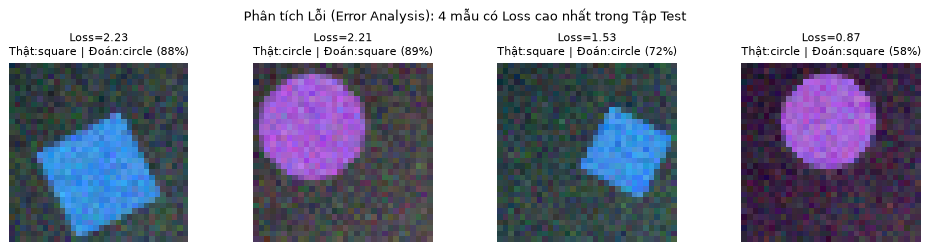

In [4]:
# Cell 4: Bước 5 & 6 — Đánh giá Cuối cùng trên Tập Test, So sánh với Baseline & Phân tích Lỗi (Error Analysis)
load_checkpoint(ckpt_capstone, model=capstone_model, device=device)
te_loss_acc, y_te_true, y_te_pred, y_te_prob = evaluate_classifier(capstone_model, te_loader, crit, device)
dl_test_metrics = compute_classification_metrics(y_te_true, y_te_pred, class_names)

print("=== BẢNG TỔNG KẾT ĐÁNH GIÁ TRÊN TẬP TEST (BASELINE ML VS DEEP LEARNING) ===")
summary_cmp = pd.DataFrame([
    {"Approach": "1. Classical ML Baseline (HOG+Color+LBP + SVM)", "Test_Acc": round(bl_test_metrics["accuracy"], 4), "Test_Macro_F1": round(bl_test_metrics["macro_f1"], 4)},
    {"Approach": "2. Deep Learning (ResidualCNN + Augmentation)", "Test_Acc": round(dl_test_metrics["accuracy"], 4), "Test_Macro_F1": round(dl_test_metrics["macro_f1"], 4)},
])
print(summary_cmp.to_string(index=False))

print("\n=== BẢNG METRIC TỪNG LỚP CỦA MÔ HÌNH DEEP LEARNING ===")
print(pd.DataFrame(dl_test_metrics["per_class"]).T.round(4).to_string())
print("\nConfusion Matrix (Hàng: Thật, Cột: Dự đoán):\n", dl_test_metrics["confusion_matrix"])

# Lưu báo cáo JSON ra outputs/reports/capstone_report.json
report_path = project_root / "outputs" / "reports" / "capstone_report.json"
report_payload = {
    "quick_run": QUICK_RUN,
    "baseline_test_accuracy": bl_test_metrics["accuracy"],
    "baseline_test_macro_f1": bl_test_metrics["macro_f1"],
    "dl_test_accuracy": dl_test_metrics["accuracy"],
    "dl_test_macro_f1": dl_test_metrics["macro_f1"],
    "checkpoint_path": str(ckpt_capstone.relative_to(project_root)),
}
report_path.write_text(json.dumps(report_payload, indent=2), encoding="utf-8")
print(f"Đã xuất báo cáo đánh giá tại: {report_path.relative_to(project_root)}")

# Phân tích lỗi (Error Analysis): Tìm các mẫu có Loss cá biệt cao nhất trên tập Test
with torch.no_grad():
    te_logits_raw = capstone_model(X_norm_t[idx_te].to(device)).cpu()
    per_sample_losses = nn.CrossEntropyLoss(reduction="none")(te_logits_raw, y_all_t[idx_te]).numpy()

hardest_local_indices = np.argsort(-per_sample_losses)[:4]
fig, axes = plt.subplots(1, 4, figsize=(11, 2.8))
for ax, loc_i in zip(axes, hardest_local_indices):
    orig_i = idx_te[loc_i]
    t_name = class_names[y_te_true[loc_i]]
    p_name = class_names[y_te_pred[loc_i]]
    conf = y_te_prob[loc_i, y_te_pred[loc_i]] * 100
    ax.imshow(images_np[orig_i])
    ax.set_title(f"Loss={per_sample_losses[loc_i]:.2f}\nThật:{t_name} | Đoán:{p_name} ({conf:.0f}%)", fontsize=8.8)
    ax.axis("off")
plt.suptitle("Phân tích Lỗi (Error Analysis): 4 mẫu có Loss cao nhất trong Tập Test", fontsize=10.5)
plt.tight_layout()
plt.show()


In [5]:
# Cell 5: Bước 7 — Chương trình Suy luận Độc lập và Hướng dẫn Thay bằng Tập Ảnh Cá nhân của Bạn
from torchvision.datasets import ImageFolder
from torchvision import transforms

# 1. Hàm suy luận độc lập từ checkpoint đã lưu
@torch.inference_mode()
def predict_single_image_from_checkpoint(rgb_img: np.ndarray, ckpt_file: Path) -> dict:
    ckpt = load_checkpoint(ckpt_file, device=device)
    model_inf = ResidualCNN(in_channels=3, num_classes=len(ckpt["class_names"]), base_channels=16)
    model_inf.load_state_dict(ckpt["model_state_dict"])
    model_inf.to(device).eval()

    cfg = ckpt["preprocessing_config"]
    mean_t = torch.tensor(cfg["mean"], device=device).view(1, 3, 1, 1)
    std_t = torch.tensor(cfg["std"], device=device).view(1, 3, 1, 1)
    x = torch.from_numpy(rgb_img).permute(2, 0, 1).unsqueeze(0).to(device, dtype=torch.float32) / 255.0
    probs = torch.softmax(model_inf((x - mean_t) / std_t), dim=1)[0].cpu().numpy()
    top_idx = int(probs.argmax())
    return {"class": ckpt["idx_to_class"][top_idx], "confidence": round(float(probs[top_idx]), 4)}


demo_pred = predict_single_image_from_checkpoint(images_np[idx_te[0]], ckpt_capstone)
print("Kiểm tra hàm Inference độc lập trên mẫu Test #0:", demo_pred, "| Nhãn thật:", class_names[labels_np[idx_te[0]]])

# 2. Mẫu code nạp Tập Ảnh Cá nhân của Bạn bằng torchvision.datasets.ImageFolder:
custom_data_dir = project_root / "data" / "my_custom_dataset"
custom_train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
print(f"Để huấn luyện trên bộ ảnh riêng, hãy đặt ảnh vào '{custom_data_dir.relative_to(project_root)}/train/<ten_lop>/' và gọi ImageFolder(root, transform=custom_train_transform)")


Kiểm tra hàm Inference độc lập trên mẫu Test #0: {'class': 'square', 'confidence': 0.9459} | Nhãn thật: square
Để huấn luyện trên bộ ảnh riêng, hãy đặt ảnh vào 'data\my_custom_dataset/train/<ten_lop>/' và gọi ImageFolder(root, transform=custom_train_transform)


## 8. Định hướng 3 Nhánh Mở rộng Tùy chọn (Optional Capstone Extensions)
Sau khi hoàn thành nhánh chính Phân loại ảnh ở trên, bạn có thể mở rộng đồ án theo 1 trong 3 nhánh sau:
1. **Nhánh Mở rộng A — Object Detection (kế thừa Bài 13)**: Đóng khung và đếm đồng thời nhiều vật thể trên ảnh bằng `fasterrcnn_mobilenet_v3_large_320_fpn`, báo cáo `mAP@0.5`.
2. **Nhánh Mở rộng B — Semantic Segmentation (kế thừa Bài 14)**: Tách mặt nạ điểm ảnh bằng `MiniUNet` với `BCE + Dice Loss`, báo cáo `IoU` và `Dice` để đo diện tích vật thể.
3. **Nhánh Mở rộng C — Anomaly Detection (kế thừa Bài 15)**: Chỉ dùng ảnh mẫu lành huấn luyện `ConvAutoencoder`, báo cáo `ROC-AUC`, `PR-AUC` và khoanh vùng vết lỗi.

---

## 9. Bảng Tiêu chí Tự Đánh giá Đồ án (`Self-Assessment Rubric`)

| Hạng mục Đánh giá | Mức Chưa Đạt (0 điểm) | Mức Đạt Cơ bản (1 điểm) | Mức Thành thạo / Chuẩn Kỹ sư (2 điểm) | Điểm tự chấm |
|---|---|---|---|---|
| **1. Kiểm định & Chia dữ liệu** | Không kiểm tra dữ liệu; chia tập sau khi `fit` scaler/PCA (bị rò rỉ dữ liệu). | Chia `train/val/test` trước khi chuẩn hóa nhưng chưa dùng `stratify` hoặc `group split`. | Có bước kiểm định dữ liệu tự động, dùng `stratify`/`group split` và đảm bảo `0%` rò rỉ dữ liệu. | `/ 2` |
| **2. Đường cơ sở (Baseline)** | Nhảy thẳng vào mạng sâu phức tạp mà không có mô hình cơ sở để đối chiếu. | Có chạy 1 mô hình ML truyền thống làm mốc so sánh. | So sánh công bằng Baseline ML (`HOG+SVM`) và Deep Learning trên cùng tập dữ liệu và cùng metric. | `/ 2` |
| **3. Huấn luyện & Checkpoint** | Không theo dõi `Validation`; lưu model ở epoch cuối cùng bị overfit. | Có theo dõi `val_loss` và lưu `state_dict`. | Lưu `checkpoint` tốt nhất kèm đầy đủ `class_to_idx` và `preprocessing_config`, có kiểm tra nạp lại. | `/ 2` |
| **4. Đánh giá & Phân tích Lỗi** | Chỉ in mỗi một con số `Accuracy`. | Có thêm `F1-score` và `Confusion Matrix`. | Báo cáo đầy đủ `Precision`, `Recall`, `Specificity`, `Macro-F1`, `Confusion Matrix` và hiển thị ảnh lỗi có `loss` cao nhất để phân tích nguyên nhân. | `/ 2` |
| **5. Suy luận & Trung thực Khoa học** | Quên `model.eval()` hoặc phóng đại kết quả trên tập dữ liệu nhỏ. | Có hàm dự đoán ảnh mới chạy đúng. | Đóng gói hàm/class Inference hoàn chỉnh, báo cáo trung thực giới hạn của dữ liệu và mô hình. | `/ 2` |
| **TỔNG ĐIỂM** | | | **Mục tiêu đạt chuẩn: $\ge 8 / 10$ điểm** | **`/ 10`** |

---

## 10. Chúc mừng Bạn Đã Hoàn thành Toàn bộ Lộ trình 23 Jupyter Notebooks!
Bạn đã đi từ những thao tác mảng `NumPy` và `Pixel` đầu tiên, qua `Xử lý ảnh cổ điển`, `Machine Learning truyền thống`, tự viết `Mạng nơ-ron từ đầu`, làm chủ `PyTorch & CNN`, tới toàn bộ các nhóm bài toán `Computer Vision` hiện đại và đóng gói triển khai thực tế.
